**Throttling Valve: Flashing Liquid Nitrogen**

In this tutorial we throttle saturated liquid nitrogen across a valve and validate the result against an equivalent DWSIM Valve model (CoolProp property package).

A valve is adiabatic and does no work, so the expansion is **isenthalpic** (h_out = h_in). When a saturated liquid is throttled to a lower pressure, part of it flashes to vapor and the stream cools to the new saturation temperature.

We assume that the valve operates at steady state.

### Inlet Specifications:

* **Component**: 100 % nitrogen
* **Mass Flow Rate**: 3600 kg/h (1 kg/s)
* **Pressure**: 5 bar
* **Temperature**: −179.155 °C (93.995 K), the saturation temperature at 5 bar

### Valve Specifications:

* **Calculation mode**: pressure drop
* **Pressure drop**: 0.5 bar (outlet 4.5 bar)
* **Valve opening**: 50 %, linear valve characteristic

With the pressure drop fixed, IDAES calculates the valve flow coefficient **Cv** from the valve flow equation `F² = Cv² · (P_in − P_out) · f(opening)²`.

---

> **Why the inlet is specified by vapor fraction and not temperature**
>
> −179.155 °C is the saturation temperature of nitrogen at 5 bar, so temperature and pressure do not fix the state. We specify the inlet with pressure and vapor fraction (x = 0, saturated liquid), as in the Turbine tutorial.

> **Adding nitrogen to IDAES**
>
> IDAES's generic (cubic/ideal) property framework cannot resolve the phase split of a *pure* component, because liquid and vapor always have the same composition. Pure fluids need IDAES's Helmholtz equation of state, which does not include nitrogen. `nitrogen_helmholtz.py` adds it: it reads the Span et al. (2000) reference equation of state for nitrogen from CoolProp's database, the same equation DWSIM's CoolProp package uses, and writes the IDAES parameter files to `helmholtz_data/`. The files are already generated; run `python nitrogen_helmholtz.py` only to regenerate them.

In [1]:
import idaes

print("IDAES version: ", idaes.__version__)

IDAES version:  2.13.0


## Setting up and solving the flowsheet

The flowsheet is Feed → Valve → Product, built in `valve.py`. Degrees of freedom are printed before and after fixing the inlet conditions and the valve specifications.

In [2]:
from valve import setup_valve_model, report_valve_properties

# Create and solve the model
model, results = setup_valve_model(
    flow_mass=1.0,  # kg/s (3600 kg/h)
    pressure_in=5e5,  # Pa
    vapor_frac_in=0.0,  # saturated liquid
    pressure_drop=0.5e5,  # Pa
    valve_opening=0.5,
)
print(results.solver.termination_condition)

prop = report_valve_properties(model)

The initial DOF is 3
The final DOF is 0
optimal

Unit : fs.feed                                                             Time: 0.0
------------------------------------------------------------------------------------
    Stream Table
                         Units          Outlet  
    Molar Flow          mole / second     35.697
    Mass Flow       kilogram / second     1.0000
    T                          kelvin     93.995
    P                          pascal 5.0000e+05
    Vapor Fraction      dimensionless     0.0000
    Molar Enthalpy       joule / mole    -2431.6

Unit : fs.valve                                                            Time: 0.0
------------------------------------------------------------------------------------
    Unit Performance

    Variables: 

    Key               : Value   : Units                                 : Fixed : Bounds
      Mechanical Work :  0.0000 :                                  watt : False : (None, None)
      Pressure Change : -50

In [3]:
from pyomo.environ import value

outlet = model.fs.valve.control_volume.properties_out[0]
print("Outlet temperature: {0:.3f} C".format(value(outlet.temperature) - 273.15))
print("Outlet vapor fraction: {0:.4f}".format(value(outlet.vapor_frac)))
print("Valve flow coefficient Cv: {0:.4f} mol/s/Pa^0.5".format(value(model.fs.valve.Cv)))

Outlet temperature: -180.480 C
Outlet vapor fraction: 0.0166
Valve flow coefficient Cv: 0.3193 mol/s/Pa^0.5


In [4]:
# Visualize (if needed)
model.fs.visualize("Valve Model")

'idaes.co re.util.diagnostics_tools.diagnostics_toolbox.DiagnosticsToolbox'.
Please update your import.  (deprecated in 2.12.0) (called from <frozen
importlib._bootstrap>:488)
'idaes.core.util.diagnostics_tools.diagnostics_toolbox.CONFIG'. Please update
your import.  (deprecated in 2.12.0) (called from <frozen
importlib._bootstrap>:488)
2026-10-30 15:36:28 [INFO] idaes.idaes_ui.fv.fsvis: Started visualization server
2026-10-30 15:36:28 [INFO] idaes.idaes_ui.fv.fsvis: Saving flowsheet to default file 'Valve Model.json' in current directory (c:\Users\VirajDesai\Downloads\Personal\Github\IDAES-PSE-Examples\Valve)
2026-10-30 15:36:28 [WARNING] idaes.idaes_ui.fv.fsvis: Flowsheet name changed: old='Valve Model' new='Valve-Model'
Flowsheet name changed to 'Valve-Model'
2026-10-30 15:36:28 [INFO] idaes.idaes_ui.fv.fsvis: Flowsheet visualization at: http://localhost:55486/app?id=Valve-Model


VisualizeResult(store=<idaes_ui.fv.persist.FileDataStore object at 0x00000236186BDA90>, port=55486, server=<idaes_ui.fv.model_server.FlowsheetServer object at 0x000002361826B950>, save_diagram=<bound method SaveDiagramScreenshot.save_diagram_screenshot of <idaes_ui.fv.save_diagram_screenshot.SaveDiagramScreenshot object at 0x0000023663E38F80>>)

## DWSIM model

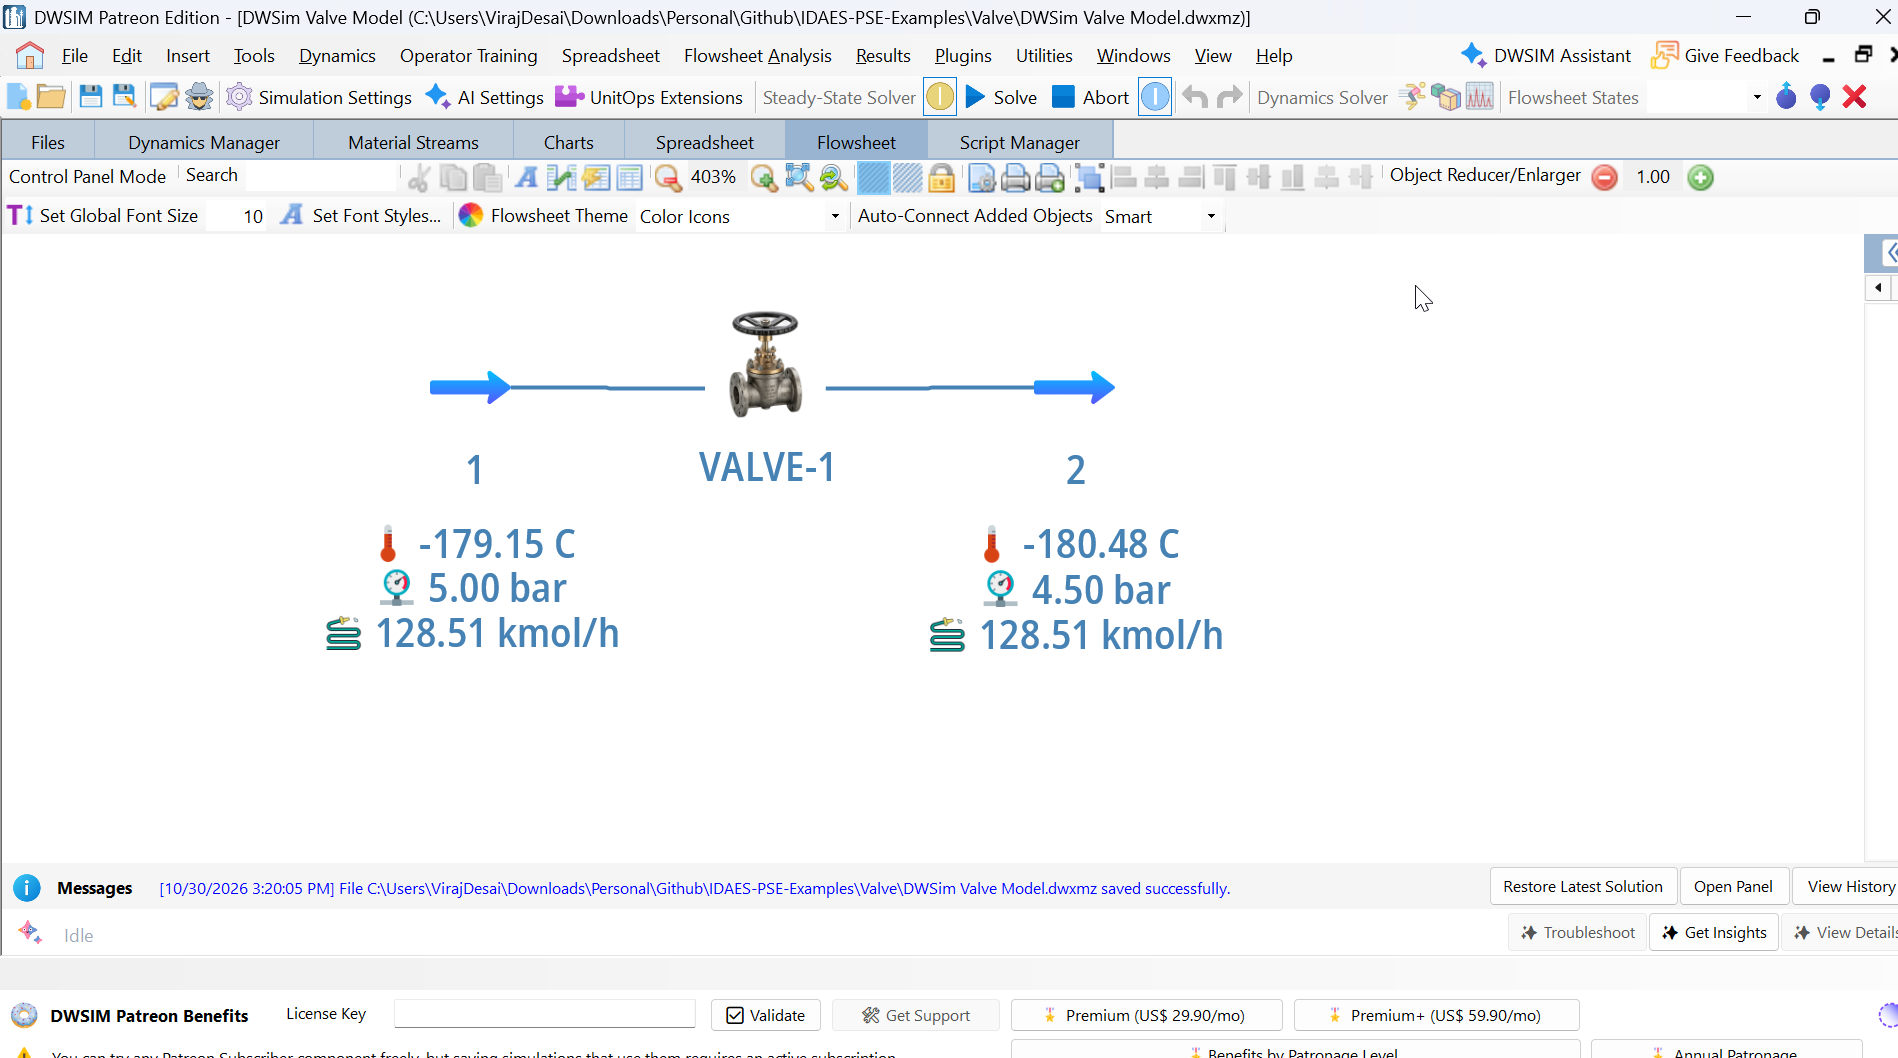

In [5]:
from IPython.display import Image
Image(filename="DWSim Valve.png")

In [6]:
import webbrowser
import tempfile
import os

def display_image_in_browser(image_path, title="Image Viewer"):
    # Create a temporary HTML file that embeds the image
    html_content = f"""
    <html>
        <head>
            <title>{title}</title>
        </head>
        <body style="text-align: center;">
            <h2>{title}</h2>
            <img src="file://{os.path.abspath(image_path)}" style="max-width:90%; max-height:90%;">
        </body>
    </html>
    """
    with tempfile.NamedTemporaryFile('w', delete=False, suffix='.html') as f:
        f.write(html_content)
        temp_html_path = f.name

    webbrowser.open(f'file://{temp_html_path}')


In [7]:
display_image_in_browser("DWSim Valve.png", title="DWSim Valve Model Check")

## Validation against DWSIM

The DWSIM results are read directly from the solved `.dwxmz` file and compared with IDAES. Both use the same reference equation of state for nitrogen, so the results should match exactly.

In [8]:
from valve import read_dwsim_results, compare_with_dwsim

dwsim = read_dwsim_results("DWSim Valve Model.dwxmz")
compare_with_dwsim(model, dwsim)

,IDAES,DWSIM,Error (%)
Inlet temperature (K),93.995018,93.995018,1.511873e-13
Outlet temperature (K),92.669898,92.669898,3.987079e-13
Temperature change (K),-1.325120,-1.325120,-1.715872e-11
Outlet pressure (Pa),450000.000000,450000.000000,0.000000e+00
Outlet vapor fraction,0.016588,0.016588,-1.271694e-11
Outlet enthalpy (kJ/kg),-86.800473,-86.800473,-5.566433e-13
